# DeepSense-X — Phase 4: Hybrid LSTM–Transformer Autoencoder
### MetroPT-3 | Google Colab CPU-friendly notebook

**Goal:** Combine LSTM sequence learning and Transformer self-attention in one reconstruction model, then evaluate it using the same sampled data protocol as Phases 2 and 3.

**Hybrid design:** The LSTM branch learns sequential patterns; the Transformer branch learns relationships across time steps. Their sequence representations are concatenated, fused, and decoded to reconstruct the original 60 × 13 sensor window.

**Lightweight settings:** 5,000 training windows, 2,000 validation windows, 10,000 test windows, up to 3 epochs, batch size 128.

**Research caution:** These are preliminary sampled event-period anomaly-detection results, not proof of advance failure forecasting. For a strict comparison, this notebook reproduces the Phase 2/3 sampling order using seed 42.

## 1. Mount Drive and set project paths

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

BASE_DIR = Path('/content/drive/MyDrive/DeepSense_X_MetroPT3')
PROCESSED_DIR = BASE_DIR / 'processed'
ARTIFACT_DIR = BASE_DIR / 'artifacts'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

PHASE1_PATH = PROCESSED_DIR / 'metropt3_phase1_windows.npz'
print('TensorFlow:', tf.__version__)
print('Phase 1 data exists:', PHASE1_PATH.exists())
if not PHASE1_PATH.exists():
    raise FileNotFoundError(f'Could not find {PHASE1_PATH}')

Mounted at /content/drive
TensorFlow: 2.21.0
Phase 1 data exists: True


## 2. Load Phase 1 data

In [2]:
phase1 = np.load(PHASE1_PATH, allow_pickle=True)
print('Available keys:', phase1.files)

required = ['X_train', 'X_val', 'X_test', 'test_window_times', 'y_test_event']
missing = [key for key in required if key not in phase1.files]
if missing:
    raise KeyError(f'Missing required keys: {missing}')

X_train = phase1['X_train'].astype('float32')
X_val = phase1['X_val'].astype('float32')
X_test = phase1['X_test'].astype('float32')
y_test = phase1['y_test_event'].astype('int32')

N_TIMESTEPS = int(X_train.shape[1])
N_FEATURES = int(X_train.shape[2])

print('Training:', X_train.shape)
print('Validation:', X_val.shape)
print('Testing:', X_test.shape)
print('Test labels:', y_test.shape)

assert X_train.ndim == 3
assert X_val.shape[1:] == (N_TIMESTEPS, N_FEATURES)
assert X_test.shape[1:] == (N_TIMESTEPS, N_FEATURES)
assert len(y_test) == len(X_test)
print('Phase 1 data loaded successfully.')

Available keys: ['X_train', 'X_val', 'X_test', 'train_scores', 'val_scores', 'test_scores', 'test_window_times', 'y_test_event', 'y_test_anomaly_pred_baseline']
Training: (214791, 60, 13)
Validation: (230389, 60, 13)
Testing: (524836, 60, 13)
Test labels: (524836,)
Phase 1 data loaded successfully.


## 3. Recreate the same lightweight samples as Phases 2 and 3
The sampling order and seed match the previous notebooks: train, validation, then test. This supports a fairer comparison.

In [3]:
SEED = 42
rng = np.random.default_rng(SEED)
tf.keras.utils.set_random_seed(SEED)

train_idx = np.sort(rng.choice(len(X_train), 5000, replace=False))
val_idx = np.sort(rng.choice(len(X_val), 2000, replace=False))
test_idx = np.sort(rng.choice(len(X_test), 10000, replace=False))

X_train_fit = X_train[train_idx]
X_val_fit = X_val[val_idx]
X_test_eval = X_test[test_idx]
y_test_eval = y_test[test_idx]

print('Training sample:', X_train_fit.shape)
print('Validation sample:', X_val_fit.shape)
print('Test sample:', X_test_eval.shape)
print('Event-labelled test windows:', int(y_test_eval.sum()))

Training sample: (5000, 60, 13)
Validation sample: (2000, 60, 13)
Test sample: (10000, 60, 13)
Event-labelled test windows: 516


## 4. Build the Hybrid LSTM–Transformer Autoencoder
**Architecture:** parallel LSTM and Transformer branches → concatenate → feature fusion → LSTM decoder → reconstruct 13 features at each time step.

The positional embedding layer explicitly preserves the batch dimension, avoiding the shape issue encountered in the initial Phase 3 model.

In [4]:
EMBED_DIM = 32
NUM_HEADS = 2
FF_DIM = 64
DROPOUT_RATE = 0.10
LSTM_UNITS = 32

@keras.utils.register_keras_serializable(package='DeepSenseX')
class PositionEmbedding(layers.Layer):
    def __init__(self, sequence_length, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.embed_dim = embed_dim
        self.embedding = layers.Embedding(
            input_dim=sequence_length,
            output_dim=embed_dim
        )

    def call(self, inputs):
        positions = tf.range(start=0, limit=tf.shape(inputs)[1], delta=1)
        position_vectors = self.embedding(positions)
        return inputs + tf.expand_dims(position_vectors, axis=0)

    def get_config(self):
        config = super().get_config()
        config.update({
            'sequence_length': self.sequence_length,
            'embed_dim': self.embed_dim
        })
        return config

def transformer_encoder_block(x, embed_dim, num_heads, ff_dim, dropout_rate):
    attention = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=dropout_rate
    )(x, x)
    x = layers.Add()([x, attention])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    ff = layers.Dense(ff_dim, activation='relu')(x)
    ff = layers.Dropout(dropout_rate)(ff)
    ff = layers.Dense(embed_dim)(ff)
    x = layers.Add()([x, ff])
    return layers.LayerNormalization(epsilon=1e-6)(x)

# Shared input
inputs = keras.Input(
    shape=(N_TIMESTEPS, N_FEATURES),
    name='sensor_window'
)

# Branch A: LSTM learns sequential patterns
lstm_branch = layers.LSTM(
    LSTM_UNITS,
    return_sequences=True,
    name='lstm_sequence_branch'
)(inputs)

# Branch B: Transformer learns cross-time relationships
transformer_branch = layers.Dense(
    EMBED_DIM,
    name='transformer_input_projection'
)(inputs)

transformer_branch = PositionEmbedding(
    N_TIMESTEPS, EMBED_DIM, name='position_embedding'
)(transformer_branch)

transformer_branch = transformer_encoder_block(
    transformer_branch,
    EMBED_DIM,
    NUM_HEADS,
    FF_DIM,
    DROPOUT_RATE
)

# Fuse both sequence representations
combined = layers.Concatenate(name='lstm_transformer_fusion')(
    [lstm_branch, transformer_branch]
)
combined = layers.Dense(32, activation='relu', name='fusion_projection')(combined)
combined = layers.Dropout(DROPOUT_RATE)(combined)

# LSTM decoder reconstructs each time step
decoded = layers.LSTM(
    LSTM_UNITS,
    return_sequences=True,
    name='lstm_decoder'
)(combined)

outputs = layers.TimeDistributed(
    layers.Dense(N_FEATURES),
    name='reconstruction'
)(decoded)

hybrid_autoencoder = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name='DeepSenseX_Hybrid_LSTM_Transformer'
)

hybrid_autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='mae'
)

hybrid_autoencoder.summary()

Model: "DeepSenseX_Hybrid_LSTM_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensor_window       │ (None, 60, 13)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_input_… │ (None, 60, 32)    │        448 │ sensor_window[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding  │ (None, 60, 32)    │      1,920 │ transformer_inpu… │
│ (PositionEmbedding) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 60, 32)    │      4,224 │ position_embeddi… │
│ (MultiHeadAttentio… │                   │            │ position_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 60, 32)    │          0 │ position_embeddi… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 60, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 60, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 60, 64)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 60, 32)    │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 60, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_sequence_bran… │ (None, 60, 32)    │      5,888 │ sensor_window[0]… │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_transformer_f… │ (None, 60, 64)    │          0 │ lstm_sequence_br… │
│ (Concatenate)       │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_projection   │ (None, 60, 32)    │      2,080 │ lstm_transformer… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 60, 32)    │          0 │ fusion_projectio… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_decoder (LSTM) │ (None, 60, 32)    │      8,320 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reconstruction      │ (None, 60, 13)    │        429 │ lstm_decoder[0][… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 27,629 (107.93 KB)

 Trainable params: 27,629 (107.93 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Verify input and output dimensions before training
Do not start training unless the output shape is exactly `(None, 60, 13)`.

In [5]:
print('Input shape:', hybrid_autoencoder.input_shape)
print('Output shape:', hybrid_autoencoder.output_shape)

assert hybrid_autoencoder.input_shape == (None, N_TIMESTEPS, N_FEATURES)
assert hybrid_autoencoder.output_shape == (None, N_TIMESTEPS, N_FEATURES)

print('SUCCESS: Hybrid model dimensions are correct!')

Input shape: (None, 60, 13)
Output shape: (None, 60, 13)
SUCCESS: Hybrid model dimensions are correct!


## 6. Train the Hybrid Autoencoder
This is a small CPU-friendly experiment: at most 3 epochs, batch size 128. Early stopping and checkpointing retain the best validation-loss model.

In [6]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        str(ARTIFACT_DIR / 'phase4_hybrid_autoencoder_best.keras'),
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

history = hybrid_autoencoder.fit(
    X_train_fit,
    X_train_fit,
    validation_data=(X_val_fit, X_val_fit),
    epochs=3,
    batch_size=128,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/3
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - loss: 0.3886
Epoch 1: val_loss improved from None to 0.70290, saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase4_hybrid_autoencoder_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase4_hybrid_autoencoder_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 12s 166ms/step - loss: 0.3254 - val_loss: 0.7029
Epoch 2/3
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - loss: 0.2148
Epoch 2: val_loss improved from 0.70290 to 0.59883, saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase4_hybrid_autoencoder_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase4_hybrid_autoencoder_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 123ms/step - loss: 0.1992 - val_loss: 0.5988
Epoch 3/3
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - loss: 0.1556
Epoch 3: val_loss improved from 0.59883 to 0.50876, saving model to /content/drive/M

## 7. Plot training and validation loss

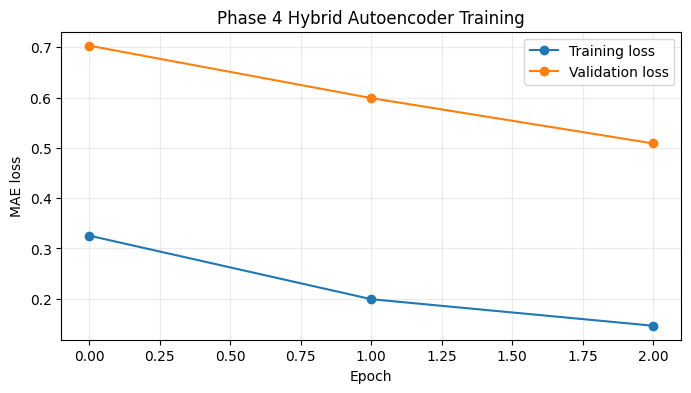

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['loss'], marker='o', label='Training loss')
plt.plot(history.history['val_loss'], marker='o', label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('MAE loss')
plt.title('Phase 4 Hybrid Autoencoder Training')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 8. Calculate reconstruction errors

In [8]:
def reconstruction_errors(model, X, batch_size=128):
    reconstructed = model.predict(X, batch_size=batch_size, verbose=1)
    errors = np.mean(np.abs(X - reconstructed), axis=(1, 2))
    return errors.astype('float32')

val_errors = reconstruction_errors(hybrid_autoencoder, X_val_fit)
test_errors = reconstruction_errors(hybrid_autoencoder, X_test_eval)

print('Validation errors:', val_errors.shape)
print('Test errors:', test_errors.shape)
print('Validation percentiles:',
      np.percentile(val_errors, [50, 90, 95, 99, 99.5, 100]))

16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step
Validation errors: (2000,)
Test errors: (10000,)
Validation percentiles: [ 0.23515564  0.73859362  2.29660865  2.56050999  6.41360571 38.73268127]


## 9. Select anomaly threshold using validation errors
Use the 99th percentile, matching Phases 2 and 3. The threshold is model-specific because reconstruction-error scales differ.

In [9]:
THRESHOLD_PERCENTILE = 99.0
anomaly_threshold = float(
    np.percentile(val_errors, THRESHOLD_PERCENTILE)
)

print('Anomaly threshold:', anomaly_threshold)
print('Validation windows above threshold:',
      int((val_errors > anomaly_threshold).sum()))
print('Validation flagged percentage:',
      f'{100 * np.mean(val_errors > anomaly_threshold):.2f}%')

Anomaly threshold: 2.5605099201202393
Validation windows above threshold: 20
Validation flagged percentage: 1.00%


## 10. Predict anomalies on sampled test windows

In [10]:
test_predictions = (test_errors > anomaly_threshold).astype('int32')

print('Predicted anomalous windows:', int(test_predictions.sum()))
print('Predicted anomaly percentage:',
      f'{100 * test_predictions.mean():.2f}%')
print('Event-labelled sampled test windows:', int(y_test_eval.sum()))

Predicted anomalous windows: 953
Predicted anomaly percentage: 9.53%
Event-labelled sampled test windows: 516


## 11. Calculate evaluation metrics

In [11]:
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, confusion_matrix, classification_report
)

precision = precision_score(y_test_eval, test_predictions, zero_division=0)
recall = recall_score(y_test_eval, test_predictions, zero_division=0)
f1 = f1_score(y_test_eval, test_predictions, zero_division=0)
accuracy = accuracy_score(y_test_eval, test_predictions)
cm = confusion_matrix(y_test_eval, test_predictions, labels=[0, 1])

print(f'Precision: {precision:.4f} ({precision*100:.2f}%)')
print(f'Recall:    {recall:.4f} ({recall*100:.2f}%)')
print(f'F1-score:  {f1:.4f} ({f1*100:.2f}%)')
print(f'Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)')
print('Confusion Matrix [[TN, FP], [FN, TP]]:')
print(cm)
print(classification_report(y_test_eval, test_predictions, zero_division=0))

Precision: 0.5383 (53.83%)
Recall:    0.9942 (99.42%)
F1-score:  0.6984 (69.84%)
Accuracy:  0.9557 (95.57%)
Confusion Matrix [[TN, FP], [FN, TP]]:
[[9044  440]
 [   3  513]]
              precision    recall  f1-score   support

           0       1.00      0.95      0.98      9484
           1       0.54      0.99      0.70       516

    accuracy                           0.96     10000
   macro avg       0.77      0.97      0.84     10000
weighted avg       0.98      0.96      0.96     10000



## 12. Plot validation error distribution and test reconstruction errors

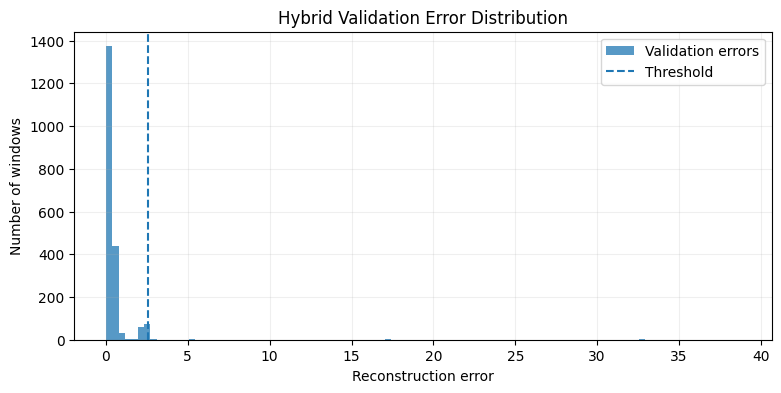

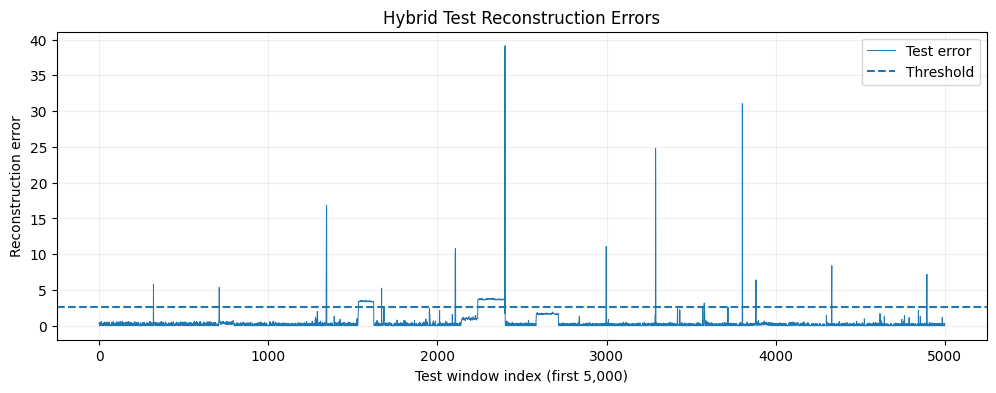

In [12]:
plt.figure(figsize=(9, 4))
plt.hist(val_errors, bins=100, alpha=0.75, label='Validation errors')
plt.axvline(anomaly_threshold, linestyle='--', label='Threshold')
plt.xlabel('Reconstruction error')
plt.ylabel('Number of windows')
plt.title('Hybrid Validation Error Distribution')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(test_errors[:5000], linewidth=0.7, label='Test error')
plt.axhline(anomaly_threshold, linestyle='--', label='Threshold')
plt.xlabel('Test window index (first 5,000)')
plt.ylabel('Reconstruction error')
plt.title('Hybrid Test Reconstruction Errors')
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 13. Event-wise sampled detection
Timestamps are aligned with the sampled test indices. This reports coverage and detection within each known event interval.

In [13]:
test_times_eval = pd.to_datetime(phase1['test_window_times'])[test_idx]

event_intervals = {
    'Event 1 (18 Apr 2020)': ('2020-04-18 00:00:00', '2020-04-19 00:00:00'),
    'Event 2 (29-30 May 2020)': ('2020-05-29 23:30:00', '2020-05-30 06:00:00'),
    'Event 3 (5-7 Jun 2020)': ('2020-06-05 10:00:00', '2020-06-07 14:30:00'),
}

rows = []
for name, (start, end) in event_intervals.items():
    mask = (
        (test_times_eval >= pd.Timestamp(start)) &
        (test_times_eval <= pd.Timestamp(end))
    )
    total = int(mask.sum())
    flagged = int(test_predictions[mask].sum())
    rows.append({
        'Event': name,
        'Sampled event windows': total,
        'Detected windows': flagged,
        'Detection rate (%)': round(100 * flagged / total, 2) if total else np.nan
    })

event_results = pd.DataFrame(rows)
display(event_results)

,Event,Sampled event windows,Detected windows,Detection rate (%)
0,Event 1 (18 Apr 2020),147,145,98.64
1,Event 2 (29-30 May 2020),47,46,97.87
2,Event 3 (5-7 Jun 2020),322,322,100.00


## 14. Compare Phase 2, Phase 3 and Phase 4
This reads the saved Phase 2 and Phase 3 metadata if present. If a metadata file is missing, the notebook still displays Phase 4 results.

In [14]:
comparison_rows = [{
    'Model': 'Phase 4 Hybrid LSTM-Transformer',
    'Precision (%)': precision * 100,
    'Recall (%)': recall * 100,
    'F1-score (%)': f1 * 100,
    'Accuracy (%)': accuracy * 100
}]

for phase_num, filename, model_name in [
    (2, 'phase2_lstm_metadata.json', 'Phase 2 LSTM'),
    (3, 'phase3_transformer_metadata.json', 'Phase 3 Transformer')
]:
    metadata_file = ARTIFACT_DIR / filename
    if metadata_file.exists():
        with open(metadata_file, 'r') as f:
            old = json.load(f)
        comparison_rows.append({
            'Model': model_name,
            'Precision (%)': old.get('precision', np.nan) * 100,
            'Recall (%)': old.get('recall', np.nan) * 100,
            'F1-score (%)': old.get('f1_score', np.nan) * 100,
            'Accuracy (%)': old.get('accuracy', np.nan) * 100
        })
    else:
        print('Metadata not found; skipping:', metadata_file)

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.sort_values('Model'))

,Model,Precision (%),Recall (%),F1-score (%),Accuracy (%)
1,Phase 2 LSTM,54.171067,99.418605,70.129870,NaN
2,Phase 3 Transformer,52.669405,99.418605,68.859060,95.36
0,Phase 4 Hybrid LSTM-Transformer,53.830010,99.418605,69.843431,95.57


## 15. Save Phase 4 model, results and metadata

In [15]:
final_model_path = ARTIFACT_DIR / 'phase4_hybrid_lstm_transformer_final.keras'
hybrid_autoencoder.save(final_model_path)

results_path = PROCESSED_DIR / 'metropt3_phase4_hybrid_results.npz'
np.savez_compressed(
    results_path,
    val_errors=val_errors,
    test_errors=test_errors,
    test_predictions=test_predictions,
    y_test_event=y_test_eval,
    test_idx=test_idx,
    threshold=np.array(anomaly_threshold, dtype='float32')
)

metadata = {
    'phase': 4,
    'model': 'Hybrid LSTM-Transformer Autoencoder',
    'input_shape': [int(N_TIMESTEPS), int(N_FEATURES)],
    'lstm_units': LSTM_UNITS,
    'embedding_dimension': EMBED_DIM,
    'attention_heads': NUM_HEADS,
    'feed_forward_dimension': FF_DIM,
    'dropout_rate': DROPOUT_RATE,
    'training_windows_available': int(len(X_train)),
    'training_windows_used': int(len(X_train_fit)),
    'validation_windows_available': int(len(X_val)),
    'validation_windows_used': int(len(X_val_fit)),
    'test_windows_available': int(len(X_test)),
    'test_windows_used': int(len(X_test_eval)),
    'threshold_percentile': float(THRESHOLD_PERCENTILE),
    'anomaly_threshold': float(anomaly_threshold),
    'precision': float(precision),
    'recall': float(recall),
    'f1_score': float(f1),
    'accuracy': float(accuracy),
    'confusion_matrix': cm.tolist(),
    'evaluation_note': 'Preliminary sampled event-period detection, not pre-failure forecasting.'
}

metadata_path = ARTIFACT_DIR / 'phase4_hybrid_metadata.json'
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=2)

print('PHASE 4 SAVED SUCCESSFULLY!')
print('Model:', final_model_path)
print('Results:', results_path)
print('Metadata:', metadata_path)

PHASE 4 SAVED SUCCESSFULLY!
Model: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase4_hybrid_lstm_transformer_final.keras
Results: /content/drive/MyDrive/DeepSense_X_MetroPT3/processed/metropt3_phase4_hybrid_results.npz
Metadata: /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase4_hybrid_metadata.json


## 16. Verify saved files

In [16]:
for path in [final_model_path, results_path, metadata_path]:
    print(('FOUND' if path.exists() else 'MISSING'), path)

FOUND /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase4_hybrid_lstm_transformer_final.keras
FOUND /content/drive/MyDrive/DeepSense_X_MetroPT3/processed/metropt3_phase4_hybrid_results.npz
FOUND /content/drive/MyDrive/DeepSense_X_MetroPT3/artifacts/phase4_hybrid_metadata.json


## Phase 4 completion checklist
- [ ] Phase 1 data loaded
- [ ] Same lightweight samples recreated
- [ ] Hybrid LSTM–Transformer architecture built
- [ ] Input/output dimensions verified
- [ ] Model trained and loss plotted
- [ ] Reconstruction errors calculated
- [ ] Validation threshold selected
- [ ] Sampled test metrics calculated
- [ ] Event-wise sample coverage checked
- [ ] Phase 2/3/4 comparison reviewed
- [ ] Model, results and metadata saved

**Research notes**
- The hybrid is a parallel-branch design: LSTM sequence output and Transformer sequence output are concatenated before reconstruction.
- Compare models using the same sample indices, labels, and threshold-selection policy.
- The 99th-percentile threshold is independently estimated from each model's validation errors; raw thresholds are not directly comparable.
- A high event-period recall is not evidence of early warning. Advance prediction requires a separate evaluation based on lead time before failure.